# E-Commerce Sales Analysis — Exploratory Data Analysis (EDA)

## 1. Project Objective

The objective of this project is to explore historical online retail transaction data to understand sales performance, identify purchasing patterns, investigate data-quality issues, and generate business insights using Python.

## 3. Business Problem

The business needs to understand its sales performance, identify its best-performing products and markets, investigate changes in revenue over time, and identify unusual or unreliable transaction records.

Exploratory Data Analysis will help uncover patterns in the data and provide evidence-based recommendations for business decisions.

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os

print(os.getcwd())

C:\Users\jyoti_ycioy5q\python\CodeAlpha Task


In [3]:
df = pd.read_excel("Online Retail.xlsx")

In [4]:
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [7]:
print("number of rows:" , df.shape[0])
print("number of columns:", df.shape[1])

number of rows: 541909
number of columns: 8


In [8]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [10]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [11]:
print("unique invoices:", df["InvoiceNo"].nunique())
print("unique products:", df["StockCode"].nunique())
print("unique customers:", df["CustomerID"].nunique())
print("unique countries", df["Country"].nunique())

unique invoices: 25900
unique products: 4070
unique customers: 4372
unique countries 38


In [12]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

### Visualize missing value

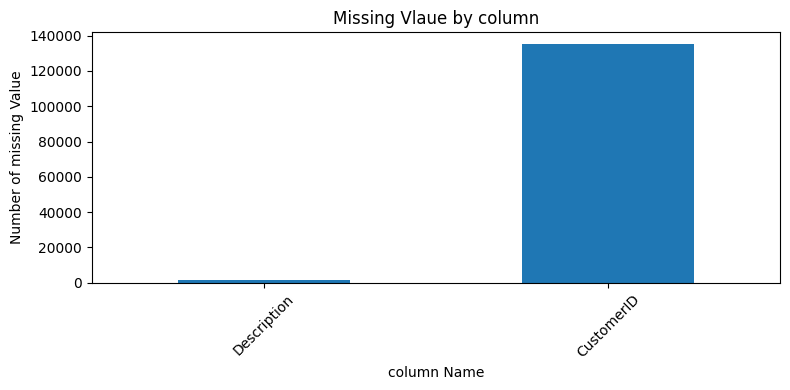

In [13]:
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

missing_counts.plot(kind="bar", figsize=(8,4))

plt.title("Missing Vlaue by column")
plt.xlabel("column Name")
plt.ylabel("Number of missing Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
df.duplicated().sum()

np.int64(5268)

In [15]:
df[["InvoiceNo", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID"]].dtypes

InvoiceNo              object
Quantity                int64
UnitPrice             float64
InvoiceDate    datetime64[us]
CustomerID            float64
dtype: object

### Identify Cancelled invoices

In [16]:
cancelled = df[df["InvoiceNo"].astype(str).str.startswith("C")]
print("Cancelled invoice rows:", len(cancelled))
print(cancelled.head())

Cancelled invoice rows: 9288
    InvoiceNo StockCode                       Description  Quantity  \
141   C536379         D                          Discount        -1   
154   C536383    35004C   SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556    PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984  PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983  PACK OF 12 BLUE PAISLEY TISSUES        -24   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00      27.50     14527.0  United Kingdom  
154 2010-12-01 09:49:00       4.65     15311.0  United Kingdom  
235 2010-12-01 10:24:00       1.65     17548.0  United Kingdom  
236 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  
237 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  


### Check negative and zero Quantities

In [17]:
print("Negative Quantities:",(df["Quantity"] < 0).sum())
print("Zero Quantities:",(df["Quantity"]== 0).sum())
print("Positive Quantities:", (df["Quantity"] >0).sum())

Negative Quantities: 10624
Zero Quantities: 0
Positive Quantities: 531285


### Remove Duplicate rows

In [18]:
print("rows before removinh duplicates:", len(df))

df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))


rows before removinh duplicates: 541909
Rows after removing duplicates: 536641


### Create Revenue Column

In [19]:
df["Revenue"] = (df["Quantity"] * df["UnitPrice"])
df[["InvoiceNo", "Description", "Quantity", "UnitPrice", "Revenue"]].head(10)

,InvoiceNo,Description,Quantity,UnitPrice,Revenue
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,WHITE METAL LANTERN,6,3.39,20.34
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34
5,536365,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30
6,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50
7,536366,HAND WARMER UNION JACK,6,1.85,11.10
8,536366,HAND WARMER RED POLKA DOT,6,1.85,11.10
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08


### Extract date-related features

In [20]:
df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["Month_Name"] = df["InvoiceDate"].dt.strftime("%B")
df["Day"] = df["InvoiceDate"].dt.day
df["Day_Name"] = df["InvoiceDate"].dt.strftime("%A")

df[["InvoiceDate","Year", "Month","Month_Name","Day","Day_Name"]].head(10)

,InvoiceDate,Year,Month,Month_Name,Day,Day_Name
0,2010-12-01 08:26:00,2010,12,December,1,Wednesday
1,2010-12-01 08:26:00,2010,12,December,1,Wednesday
2,2010-12-01 08:26:00,2010,12,December,1,Wednesday
3,2010-12-01 08:26:00,2010,12,December,1,Wednesday
4,2010-12-01 08:26:00,2010,12,December,1,Wednesday
5,2010-12-01 08:26:00,2010,12,December,1,Wednesday
6,2010-12-01 08:26:00,2010,12,December,1,Wednesday
7,2010-12-01 08:28:00,2010,12,December,1,Wednesday
8,2010-12-01 08:28:00,2010,12,December,1,Wednesday
9,2010-12-01 08:34:00,2010,12,December,1,Wednesday


### Visualize the Revenue Distribution

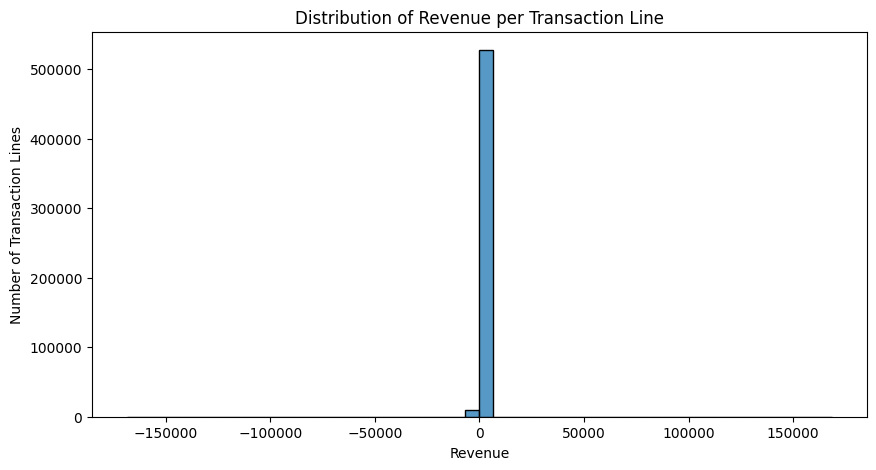

In [21]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Revenue", bins=50)
plt.title("Distribution of Revenue per Transaction Line")
plt.xlabel("Revenue")
plt.ylabel("Number of Transaction Lines")
plt.show()

### Revenue by country

In [22]:
country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

country_revenue.head(10)

Country
United Kingdom    8167128.184
Netherlands        284661.540
EIRE               262993.380
Germany            221509.470
France             197317.110
Australia          137009.770
Switzerland         56363.050
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: Revenue, dtype: float64

### Revenue by month

In [23]:
monthly_revenue = (
    df.groupby(["Year", "Month"])["Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue["Year_Month"] = (
    monthly_revenue["Year"].astype(str)
    + "-"
    + monthly_revenue["Month"].astype(str).str.zfill(2)
)

monthly_revenue.head()

,Year,Month,Revenue,Year_Month
0,2010,12,746723.610,2010-12
1,2011,1,558448.560,2011-01
2,2011,2,497026.410,2011-02
3,2011,3,682013.980,2011-03
4,2011,4,492367.841,2011-04


### Find the Highest and Lowest Revenue Month

In [27]:
highest_month = monthly_revenue.loc[
    monthly_revenue["Revenue"].idxmax()
]

lowest_month = monthly_revenue.loc[
    monthly_revenue["Revenue"].idxmin()
]

print("Highest Revenue Month:")
print(highest_month)

print("\nLowest Revenue Month:")
print(lowest_month)

Highest Revenue Month:
Year               2011
Month                11
Revenue       1456145.8
Year_Month      2011-11
Name: 11, dtype: object

Lowest Revenue Month:
Year               2011
Month                12
Revenue       432701.06
Year_Month      2011-12
Name: 12, dtype: object


### Overall Sales Performance

In [26]:
total_revenue = df["Revenue"].sum()

total_invoices = df["InvoiceNo"].nunique()

total_customers = df["CustomerID"].nunique()

total_quantity = df["Quantity"].sum()

print("Total Revenue:", round(total_revenue, 2))
print("Total Invoices:", total_invoices)
print("Total Customers:", total_customers)
print("Total Quantity Sold:", total_quantity)

Total Revenue: 9726006.95
Total Invoices: 25900
Total Customers: 4372
Total Quantity Sold: 5162502


### Find the top 5 Products by Revenue

In [28]:
top_products = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top_products

Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
Name: Revenue, dtype: float64

### Find the Most Sold Product by Quantity

In [29]:
top_quantity_products = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top_quantity_products

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS    53751
JUMBO BAG RED RETROSPOT              47260
POPCORN HOLDER                       36322
ASSORTED COLOUR BIRD ORNAMENT        36282
PACK OF 72 RETROSPOT CAKE CASES      36016
Name: Quantity, dtype: int64

### Find the Country with the Highest Number of Invoices

In [30]:
country_invoices = (
    df.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

country_invoices.head(10)

Country
United Kingdom    23494
Germany             603
France              461
EIRE                360
Belgium             119
Spain               105
Netherlands         101
Switzerland          74
Portugal             71
Australia            69
Name: InvoiceNo, dtype: int64

### Weekday vs Weekend Revenue

In [31]:
df["Day_Type"] = df["InvoiceDate"].dt.dayofweek.map(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

day_revenue = (
    df.groupby("Day_Type")["Revenue"]
    .agg(["mean", "sum", "count"])
)

day_revenue

,mean,sum,count
Day_Type,,,
Weekday,18.840625,8927347.493,473835
Weekend,12.716292,798659.461,62806


### Correlation Analysis

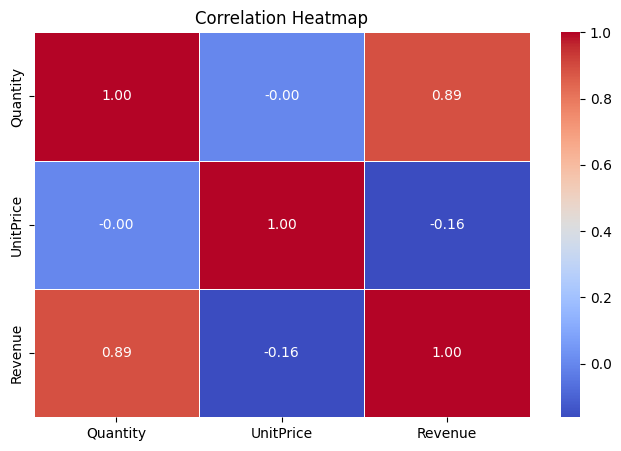

In [24]:
correlation = df[
    ["Quantity", "UnitPrice", "Revenue"]
].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

### Data Quality Summary

In [32]:
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")

data_quality = pd.DataFrame({
    "Data Quality Check": [
        "Missing Customer IDs",
        "Missing Product Descriptions",
        "Exact Duplicate Rows",
        "Negative Quantities",
        "Zero Unit Prices",
        "Cancellation Transaction Rows",
        "Unique Cancelled Invoices"
    ],
    "Count": [
        df["CustomerID"].isna().sum(),
        df["Description"].isna().sum(),
        df.duplicated().sum(),
        (df["Quantity"] < 0).sum(),
        (df["UnitPrice"] == 0).sum(),
        cancelled.sum(),
        df.loc[cancelled, "InvoiceNo"].nunique()
    ]
})

display(data_quality)

,Data Quality Check,Count
0,Missing Customer IDs,135037
1,Missing Product Descriptions,1454
2,Exact Duplicate Rows,0
3,Negative Quantities,10587
4,Zero Unit Prices,2510
5,Cancellation Transaction Rows,9251
6,Unique Cancelled Invoices,3836


# Business Insights & Recommendations

## 1. Overall Sales Performance

**Insight:** The dataset records total revenue of 9,726,006.95 across 25,900 unique invoices and 4,372 unique customers, with a total net quantity of 5,162,502 units.

**Recommendation:** The business should monitor revenue, invoice volume, and customer activity regularly to evaluate overall sales performance.

## 2. Country Performance

**Insight:** The United Kingdom generated the highest revenue (8,167,128.18), followed by the Netherlands (284,661.54) and EIRE (262,993.38). The UK also recorded the highest number of unique invoices (23,494).

**Recommendation:** The business should continue analyzing its strong UK market while exploring opportunities to increase sales in other countries, particularly the Netherlands, EIRE, and Germany.

## 3. Monthly Sales Performance

**Insight:** November 2011 recorded the highest monthly revenue of 1,456,145.80, while December 2011 recorded the lowest revenue of 432,701.06.

**Recommendation:** The business should investigate the factors behind November's strong performance and examine the December decline to identify potential seasonal or operational influences.

## 4. Product Revenue Performance

**Insight:** DOTCOM POSTAGE generated the highest recorded revenue (206,245.48), followed by REGENCY CAKESTAND 3 TIER (164,459.49). Among physical merchandise, REGENCY CAKESTAND 3 TIER was the highest revenue-generating product in the top-five list.

**Recommendation:** The business should evaluate the performance of its leading merchandise products and investigate postage revenue separately from product sales.

## 5. Product Quantity Performance

**Insight:** WORLD WAR 2 GLIDERS ASSTD DESIGNS recorded the highest quantity sold, with 53,751 units. JUMBO BAG RED RETROSPOT appeared in both the top-five revenue and top-five quantity lists.

**Recommendation:** The business should monitor inventory levels for frequently purchased products and evaluate whether high-demand products require more frequent stock replenishment.

## 6. Customer and Transaction Patterns

**Insight:** The United Kingdom recorded 23,494 unique invoices, substantially more than other countries. Weekdays generated higher average transaction-line revenue (18.84) than weekends (12.72). Total weekday revenue was 8,927,347.49, compared with 798,659.46 on weekends.

**Recommendation:** The business should investigate weekday purchasing behaviour and consider targeted weekend promotions to encourage additional customer activity.

## 7. Data Quality

**Insight:** The dataset contains 135,037 missing Customer IDs, 1,454 missing product descriptions, 10,587 negative-quantity records, 2,510 zero-unit-price records, and 9,251 cancellation transaction rows across 3,836 unique cancelled invoices. No exact duplicate rows were identified.

**Recommendation:** The business should investigate missing values, review zero-priced transactions, and analyze returns and cancellations separately to improve the reliability of sales reporting.

## Conclusion

The analysis highlights the United Kingdom as the dominant revenue-generating market, November 2011 as the strongest month, and several products with high revenue and sales volume. It also identifies data-quality issues that should be addressed before making final business decisions.